<a href="https://colab.research.google.com/github/22495521/99-multiplication-table/blob/main/transformer_gushi_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 實作 Transformer 語言模型，生成古文 (Colab 版)

訓練資料為 `data.json`，內容是論語、中庸、孟子等 36 章古文。

**使用前請先把 `data.json` 上傳到 Google Drive**，
預設位置為 `MyDrive/colab_file/data.json`(可在下方 `DRIVE_DIR` 修改)。

記得先切換到 GPU：`執行階段` → `變更執行階段類型` → `T4 GPU`。

## 檢查 GPU 環境

In [1]:
!nvidia-smi -L

import torch
print("torch", torch.__version__, "| CUDA 可用：", torch.cuda.is_available())

GPU 0: Tesla T4 (UUID: GPU-2a8d8b94-51e9-45b8-0a91-4f158b8c5c45)
torch 2.11.0+cu130 | CUDA 可用： True


## 掛載 Google Drive 並載入訓練資料

In [2]:
from pathlib import Path
import shutil

DATA_SOURCE = "drive"  # "drive" 或 "upload"

DRIVE_DIR = Path("/content/drive/MyDrive/colab_file")
JSON_NAME = "data.json"
CONTENT = Path("/content")

if DATA_SOURCE == "drive":
    from google.colab import drive

    drive.mount("/content/drive")
    # 複製到本機 /content，讀取比直接讀 Drive 快
    DATA_PATH = CONTENT / JSON_NAME
    shutil.copy(DRIVE_DIR / JSON_NAME, DATA_PATH)
    OUTPUT_DIR = DRIVE_DIR / "gushi_outputs"
else:
    from google.colab import files

    uploaded = files.upload()  # 手動選 data.json
    DATA_PATH = CONTENT / next(iter(uploaded))
    OUTPUT_DIR = CONTENT / "gushi_outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_PATH = OUTPUT_DIR / "gushi_transformer.pt"

assert DATA_PATH.exists(), f"找不到 {DATA_PATH}"
print("資料集位置：", DATA_PATH)
print("輸出位置：", OUTPUT_DIR)

Mounted at /content/drive
資料集位置： /content/data.json
輸出位置： /content/drive/MyDrive/colab_file/gushi_outputs


## 載入套件

In [3]:
import json
import math
import time

import torch
import torch.nn as nn
from torch.nn import TransformerEncoder, TransformerEncoderLayer
import matplotlib.pyplot as plt

## 設定參數

In [4]:
BLOCK_SIZE = 192  # context 長度：預測下一個字時最多往回看幾個字
BATCH_SIZE = 64  # 批量(Colab GPU 記憶體夠，可比本機大)
VAL_FRAC = 0.05  # 最後 5% 的字留著當驗證集
EOS = "\n"  # 段落結尾字元，也當作生成的停止符

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(1337)
device

device(type='cuda')

## 載入古文訓練資料

`data.json` 的格式是 `[{"chapter": ..., "paragraphs": [...]}, ...]`，
把所有段落接成一條長字元流，段落之間插入 `EOS`，模型才學得到「一段話到這裡結束」。

In [5]:
with open(DATA_PATH, encoding="utf-8") as f:
    data = json.load(f)

paragraphs = [p.strip() for ch in data for p in ch.get("paragraphs", []) if p.strip()]
text = EOS.join(paragraphs) + EOS

# 建字表：出現過的字排序後，index 就是該字的 id
chars = sorted(set(text))
stoi = {ch: i for i, ch in enumerate(chars)}
stream = torch.tensor([stoi[ch] for ch in text], dtype=torch.long)

# 照順序切，不隨機打散，驗證集才是模型真的沒看過的內容
n_val = int(len(stream) * VAL_FRAC)
train_stream, val_stream = stream[:-n_val], stream[-n_val:]

print("段落數量", len(paragraphs))
print("總字數", len(text))
print("字種數量", len(chars))
print("train / val tokens", len(train_stream), "/", len(val_stream))
print("開頭 50 字：", text[:50])

段落數量 1257
總字數 74271
字種數量 2340
train / val tokens 70558 / 3713
開頭 50 字： 天命之謂性，率性之謂道，修道之謂教。道也者，不可須臾離也，可離非道也。是故君子戒慎乎其所不睹，恐懼乎


## 準備訓練批次

目標 `y` 就是輸入 `x` 往右位移一格：x = 「學而時習」，y = 「而時習之」，
等於一次算出 `BLOCK_SIZE` 個位置的預測。

In [6]:
def get_batch(data_stream, batch_size=BATCH_SIZE):
    i = torch.randint(len(data_stream) - BLOCK_SIZE - 1, (batch_size,))
    x = torch.stack([data_stream[j : j + BLOCK_SIZE] for j in i])
    y = torch.stack([data_stream[j + 1 : j + 1 + BLOCK_SIZE] for j in i])
    return x.to(device), y.to(device)


xb, yb = get_batch(train_stream)
print("x 維度", xb.shape, "| y 維度", yb.shape)
print("x:", "".join(chars[i] for i in xb[0, :20].tolist()))
print("y:", "".join(chars[i] for i in yb[0, :20].tolist()))

x 維度 torch.Size([64, 192]) | y 維度 torch.Size([64, 192])
x: 不知也，則為狼疾人也。飲食之人，則人賤之
y: 知也，則為狼疾人也。飲食之人，則人賤之矣


## 定義神經網路參數

In [7]:
D_MODEL = 256  # 每個字的向量維度
NHEAD = 4  # multi-head attention 的 head 數，必須能整除 D_MODEL
D_HID = 1024  # 每層裡面 feed-forward 的中間層寬度
NLAYERS = 4  # 疊幾層 encoder layer
DROPOUT = 0.2  # 資料只有 7 萬多字，很容易背起來，所以 dropout 開大一點

## 定義位置編碼

attention 本身看不出字的先後，所以把位置資訊用 sin/cos 加進向量裡。
這組值固定不訓練，用 `register_buffer` 存才會跟著 `.to(device)` 搬家。

In [8]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout, max_len):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        position = torch.arange(max_len).unsqueeze(1)  # [max_len, 1]
        # 不同維度用不同波長，低維變化快、高維變化慢
        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )
        pe = torch.zeros(1, max_len, d_model)
        pe[0, :, 0::2] = torch.sin(position * div_term)  # 偶數維放 sin
        pe[0, :, 1::2] = torch.cos(position * div_term)  # 奇數維放 cos
        self.register_buffer("pe", pe)

    def forward(self, x):
        # x: [batch, seq_len, d_model]，只取前 seq_len 個位置相加
        return self.dropout(x + self.pe[:, : x.size(1)])

## 定義 Transformer 模型

輸入一串字 id，輸出每個位置「下一個字」的分數。
關鍵是 causal mask：第 i 個位置只能看到 0..i，不然就直接偷看答案了。

In [9]:
class TransformerModel(nn.Module):
    def __init__(
        self,
        ntoken,  # 字種數，也就是輸出要分幾類
        d_model=D_MODEL,
        nhead=NHEAD,
        d_hid=D_HID,
        nlayers=NLAYERS,
        dropout=DROPOUT,
        block_size=BLOCK_SIZE,
    ):
        super().__init__()
        self.d_model = d_model
        self.block_size = block_size
        self.embedding = nn.Embedding(ntoken, d_model)  # 字 id -> 向量
        self.pos_encoder = PositionalEncoding(d_model, dropout, block_size)
        layer = TransformerEncoderLayer(
            d_model,
            nhead,
            d_hid,
            dropout,
            batch_first=True,  # 輸入用 [batch, seq, feature]
            norm_first=True,  # pre-norm，小資料上比較穩、不太需要調 lr
        )
        self.transformer_encoder = TransformerEncoder(
            layer, nlayers, enable_nested_tensor=False
        )
        self.norm = nn.LayerNorm(d_model)  # pre-norm 架構最後要再 norm 一次
        self.linear = nn.Linear(d_model, ntoken)  # 向量 -> 每個字的分數

    def forward(self, src):
        """src: [batch, seq_len] -> logits [batch, seq_len, ntoken]"""
        # 上三角是 -inf 的 causal mask，擋住未來的字
        mask = nn.Transformer.generate_square_subsequent_mask(
            src.size(1), device=src.device
        )
        # 乘 sqrt(d_model) 放大 embedding，讓它和位置編碼的量級相當
        x = self.embedding(src) * math.sqrt(self.d_model)
        x = self.pos_encoder(x)
        x = self.transformer_encoder(x, mask=mask, is_causal=True)
        return self.linear(self.norm(x))


model = TransformerModel(len(chars)).to(device)
print(f"模型參數 {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")
print("輸出維度", model(xb[:2]).shape)

模型參數 4.36M
輸出維度 torch.Size([2, 192, 2340])


## 設定損失函數、優化器(optimizer)

In [10]:
STEPS = 4000
LR = 3e-4
WARMUP = 200  # 前 200 步把 lr 從 0 線性拉上來，避免一開始就爆掉

# 設定損失函數
criterion = nn.CrossEntropyLoss()

# 設定優化器(optimizer)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.1)

# lr 排程：先 warmup 線性上升，之後 cosine 衰減到 0
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda s: (s + 1) / WARMUP
    if s < WARMUP
    else 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (STEPS - WARMUP))),
)

## 進行模型訓練

每 250 步在驗證集上評估一次，只有 val loss 進步才存檔，避免後面過擬合的權重蓋掉好的。
權重會存到 Drive 的 `gushi_outputs/`，Colab 斷線後重跑也不會遺失。

ppl(perplexity) = exp(loss)，大致是「模型在幾個字之間猶豫」，越小越好。

In [11]:
EVAL_EVERY = 250
EVAL_BATCHES = 20  # 每次驗證取幾個 batch 平均，減少隨機取樣的誤差


@torch.no_grad()
def evaluate(data_stream):
    model.eval()  # 關掉 dropout
    total = 0.0
    for _ in range(EVAL_BATCHES):
        x, y = get_batch(data_stream)
        # flatten(0, 1) 把 [batch, seq, ntoken] 壓成 [batch*seq, ntoken]
        total += criterion(model(x).flatten(0, 1), y.flatten()).item()
    model.train()
    return total / EVAL_BATCHES


# 模型訓練
history = []
best = float("inf")
t0 = time.time()
model.train()

for step in range(1, STEPS + 1):
    x, y = get_batch(train_stream)
    loss = criterion(model(x).flatten(0, 1), y.flatten())

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 0.5)  # 砍掉過大的梯度
    optimizer.step()
    scheduler.step()

    if step % EVAL_EVERY == 0 or step == STEPS:
        val = evaluate(val_stream)
        history.append((step, loss.item(), val))
        print(
            "[%d/%d] Loss_train: %.4f Loss_val: %.4f ppl: %.1f lr: %.2e %.0fs"
            % (
                step,
                STEPS,
                loss.item(),
                val,
                math.exp(val),
                scheduler.get_last_lr()[0],
                time.time() - t0,
            )
        )
        # chars 一起存，重新載入時才還原得出同一份字表
        if val < best:
            best = val
            torch.save(
                {"model": model.state_dict(), "chars": chars, "val": val}, CKPT_PATH
            )
            print("  -> 存檔", CKPT_PATH)

print("訓練完成，最佳 val loss %.4f" % best)

[250/4000] Loss_train: 4.4353 Loss_val: 4.6584 ppl: 105.5 lr: 3.00e-04 30s
  -> 存檔 /content/drive/MyDrive/colab_file/gushi_outputs/gushi_transformer.pt
[500/4000] Loss_train: 3.9162 Loss_val: 4.5334 ppl: 93.1 lr: 2.95e-04 61s
  -> 存檔 /content/drive/MyDrive/colab_file/gushi_outputs/gushi_transformer.pt
[750/4000] Loss_train: 3.6559 Loss_val: 4.6141 ppl: 100.9 lr: 2.85e-04 94s
[1000/4000] Loss_train: 3.4693 Loss_val: 4.6786 ppl: 107.6 lr: 2.68e-04 126s
[1250/4000] Loss_train: 3.3812 Loss_val: 4.7593 ppl: 116.7 lr: 2.47e-04 158s
[1500/4000] Loss_train: 3.2121 Loss_val: 4.8210 ppl: 124.1 lr: 2.21e-04 192s
[1750/4000] Loss_train: 3.1262 Loss_val: 4.8939 ppl: 133.5 lr: 1.93e-04 227s
[2000/4000] Loss_train: 3.0365 Loss_val: 4.9244 ppl: 137.6 lr: 1.62e-04 261s
[2250/4000] Loss_train: 3.0099 Loss_val: 4.9889 ppl: 146.8 lr: 1.31e-04 295s
[2500/4000] Loss_train: 2.9393 Loss_val: 5.0038 ppl: 149.0 lr: 1.01e-04 330s
[2750/4000] Loss_train: 2.9146 Loss_val: 5.0653 ppl: 158.4 lr: 7.32e-05 364s
[3000/

## 畫出訓練曲線

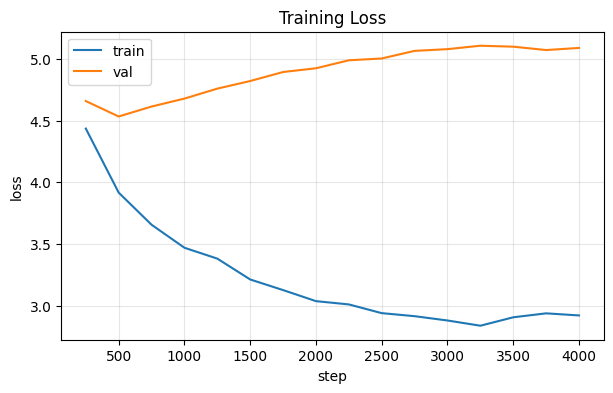

In [12]:
steps = [h[0] for h in history]
plt.figure(figsize=(7, 4))
plt.plot(steps, [h[1] for h in history], label="train")
plt.plot(steps, [h[2] for h in history], label="val")
plt.xlabel("step")
plt.ylabel("loss")
plt.title("Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 新資料預測

丟一段開頭，模型自回歸往後接：每次把整段餵進去，取最後一個位置的預測當下一個字。

- `temperature` 越低越保守(接近照抄原文)，越高越亂
- `top_k` 每步只從機率最高的 k 個字裡抽，擋掉長尾的怪字

In [13]:
@torch.no_grad()
def generate(prompt, length=120, temperature=0.9, top_k=40, stop_at_eos=True):
    model.eval()

    # 訓練資料沒出現過的字沒有 id，只能略過，不然會 KeyError
    unknown = [ch for ch in prompt if ch not in stoi]
    if unknown:
        print("（這些字不在訓練資料裡，已忽略：%s）" % "".join(unknown))

    idx = torch.tensor([[stoi[ch] for ch in prompt if ch in stoi]], device=device)
    for _ in range(length):
        # 只取最後 block_size 個字，超過 context 長度位置編碼也不夠長
        logits = model(idx[:, -model.block_size :])[:, -1, :] / temperature
        # top-k：把第 k 名以下的分數壓成 -inf，softmax 後機率就是 0
        kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, -1:]
        logits = logits.masked_fill(logits < kth, float("-inf"))
        # 用抽樣而不是 argmax，不然每次都生成同一句
        next_id = torch.multinomial(torch.softmax(logits, dim=-1), 1)
        if stop_at_eos and chars[next_id.item()] == EOS:
            break
        idx = torch.cat([idx, next_id], dim=1)

    return "".join(chars[i] for i in idx[0].tolist())


print(generate("子曰：「學而"))

子曰：「學而求諸其鄰。」


### 多生幾則看看

In [14]:
for prompt in ["子曰：", "君子", "孟子見梁惠王"]:
    print("=== %s ===" % prompt)
    print(generate(prompt, length=100, temperature=0.8))
    print()

=== 子曰： ===
子曰：「然則有財。」

=== 君子 ===
君子於中和而已矣，則去之所同，則如彼濯濯孺子，可以為君者有餘歲，則有慶以為所以待大哉？」

=== 孟子見梁惠王 ===
孟子見梁惠王，豈不遇於利吾見孟子。」



## 之後要重用模型

訓練好的權重在 Drive 裡，下次開新的 Colab 只要執行前面的套件、參數、模型定義，
再跑這一格載入權重，就能直接生成，不用重新訓練。

In [15]:
ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)
chars = ckpt["chars"]
stoi = {ch: i for i, ch in enumerate(chars)}
model = TransformerModel(len(chars)).to(device)
model.load_state_dict(ckpt["model"])
model.eval()
print("載入 val loss %.4f 的權重" % ckpt["val"])
print(generate("子曰：「君子"))

載入 val loss 4.5334 的權重
子曰：「君子之所覆以為不義者，不亦將以禮，不可與君子。」
